## Step 0: Working folder on Google Drive (optional)
Google Drive is mounted and a folder on it becomes the working folder, so every forecast file is stored
permanently. An interrupted run then resumes from the last stored origin. Skip this step when the data
and forecast files are uploaded directly to the Colab session.

In [1]:
import os, shutil
from google.colab import drive
drive.mount("/content/drive")
work_dir = "/content/drive/MyDrive/lstm_rolling"
os.makedirs(work_dir, exist_ok=True)
os.chdir(work_dir)
print(os.getcwd())
print(os.listdir())

Mounted at /content/drive
/content/drive/MyDrive/lstm_rolling
['merged_data_clean.csv', 'backup_before_cpi_fix', 'forecasts_k1000.csv', 'forecasts_common_k750.csv', 'forecasts_common_k1250.csv', 'figure2_cumulative_sse.png', 'forecasts_k1000_u64.csv', 'forecasts_k1000_seed7.csv', 'figure_exchange_rate.png', 'figure_log_returns.png', 'figure_actual_vs_forecast.png', 'article_figures_hd', 'article_figures_hd.zip']


## Step 1: Libraries and data import
This step loads the libraries and the dataset. The `arch` library estimates the
ARIMAX-GARCH model by quasi-maximum likelihood, `statsmodels` provides the
stationarity, cointegration and diagnostic tests, and Keras 3 with the JAX backend
trains the LSTM network. The dataset contains the daily JISDOR rate (fx), the upper
limit of the Federal Funds target range (ffr), the BI policy rate (bi) and the
Indonesian CPI (cpi) from 2 April 2018 to 27 July 2026.

In [ ]:
!pip install -q arch==8.0.0

import os
os.environ["KERAS_BACKEND"] = "jax"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from arch import arch_model
from arch.unitroot import ADF, PhillipsPerron
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.tsa.stattools import pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import keras

print("Keras backend:", keras.backend.backend())

DATA_PATH = "merged_data_clean.csv"
MAX_EPOCHS = 100                       # upper limit of training epochs
STEP_ORIGINS = 1                       # 1 = every forecast origin

df = pd.read_csv(DATA_PATH, parse_dates=["date"])
print(df.shape)
df.head()

Keras backend: jax
(2004, 5)


,date,fx,ffr,cpi,bi
0,2018-04-02,13750,1.75,101.093629,4.25
1,2018-04-03,13765,1.75,101.093629,4.25
2,2018-04-04,13760,1.75,101.093629,4.25
3,2018-04-05,13767,1.75,101.093629,4.25
4,2018-04-06,13771,1.75,101.093629,4.25


## Step 2: Data cleaning and frequency alignment
JISDOR is published only on Indonesian trading days, so non-trading days are absent
rather than interpolated. The policy rates are carried forward from each announcement
to the next. The CPI of month M is placed from its BPS release date, which is the
first trading day of month M+1 except for the December 2025 CPI released on
5 January 2026, so no CPI value is used before it is published. The March 2018 CPI
needed in April 2018 is derived from the April 2018 CPI and the April 2018 monthly
inflation of 0.10%. The cell reloads the raw file, so it gives the same result
however many times it runs.

In [ ]:
# 1. Reload the raw file so this cell gives the same result however many times it runs
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
print("Missing values per column:\n", df.isna().sum())
print("Duplicated dates:", df["date"].duplicated().sum())
df = df.sort_values("date").reset_index(drop=True)

# 2. CPI of month M applies from its BPS release date (first trading day of M+1, with verified exceptions)
month = df["date"].dt.to_period("M")
cpi_ref = df.groupby(month)["cpi"].first()                     # CPI of reference month M
cpi_ref.loc[pd.Period("2018-03", "M")] = cpi_ref.loc[pd.Period("2018-04", "M")] / (1 + 0.10 / 100)
cpi_ref = cpi_ref.sort_index()

first_td = df.groupby(month)["date"].min()
release = pd.Series({m: first_td.get(m + 1) for m in cpi_ref.index})
release[pd.Period("2025-12", "M")] = pd.Timestamp("2026-01-05")   # BPS press release 2527

sched = (pd.DataFrame({"release": pd.to_datetime(release.values),
                       "cpi_rel": cpi_ref.reindex(release.index).values})
         .dropna().sort_values("release"))
df = pd.merge_asof(df, sched, left_on="date", right_on="release", direction="backward")
df["cpi"] = df["cpi_rel"]
df = df.drop(columns=["release", "cpi_rel"])

# 3. Checks
assert df["cpi"].notna().all()
cpi_check = df.set_index("date")["cpi"]
assert round(cpi_check.iloc[0], 4) == 100.9926
assert round(cpi_check.loc["2018-05-02"], 4) == 101.0936
print("First date:", df["date"].min().date(), "| Last date:", df["date"].max().date())
print("Number of trading days:", len(df))

Missing values per column:
 date    0
fx      0
ffr     0
cpi     0
bi      0
dtype: int64
Duplicated dates: 0
First date: 2018-04-02 | Last date: 2026-07-27
Number of trading days: 2004


## Step 3: Log returns and descriptive statistics
The forecast target is the percent log return r_t = 100 (ln X_t − ln X_{t−1}).
The three exogenous variables enter as first differences. The 2,004 levels give
2,003 log returns.

Number of log returns: 2003
count    2003.000000
mean        0.013433
std         0.400292
min        -2.500052
25%        -0.167402
50%         0.035010
75%         0.213524
max         3.508254
dtype: float64
Skewness: 0.3393390134018062 | Excess kurtosis: 8.311685223354514


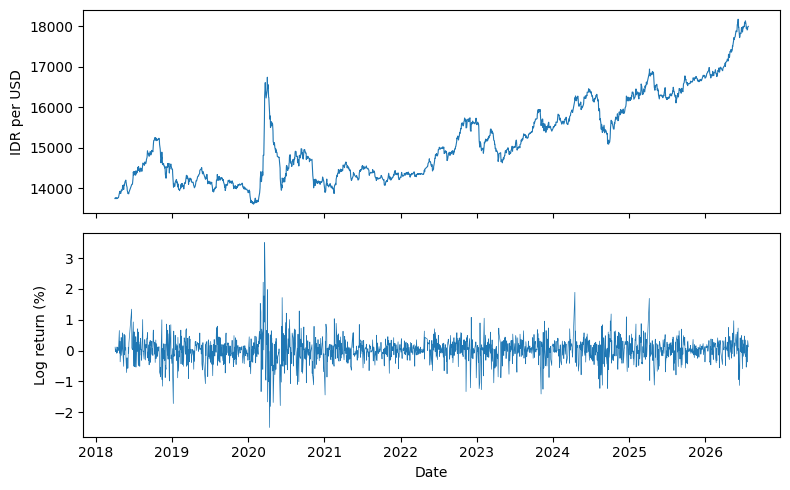

In [ ]:
level = df["fx"].to_numpy(float)
r = 100 * np.diff(np.log(level))                       # r[i]: return from day i to day i+1
dW = np.column_stack([np.diff(df[c].to_numpy(float)) for c in ["ffr", "bi", "cpi"]])
ret_dates = df["date"].iloc[1:].reset_index(drop=True)
n_ret = len(r)
print("Number of log returns:", n_ret)

print(pd.Series(r).describe())
print("Skewness:", stats.skew(r), "| Excess kurtosis:", stats.kurtosis(r))

fig, ax = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
ax[0].plot(df["date"], level, lw=0.8)
ax[0].set_ylabel("IDR per USD")
ax[1].plot(ret_dates, r, lw=0.5)
ax[1].set_ylabel("Log return (%)")
ax[1].set_xlabel("Date")
plt.tight_layout()
plt.show()

## Step 4: Stationarity tests
The ADF and Phillips-Perron tests share the null hypothesis of a unit root. A series
is I(1) when the null is not rejected in levels but is rejected after first
differencing.

In [ ]:
def unit_root_row(name, x):
    return {
        "series": name,
        "ADF level p": ADF(x, trend="c").pvalue,
        "PP level p": PhillipsPerron(x, trend="c").pvalue,
        "ADF diff p": ADF(np.diff(x), trend="c").pvalue,
        "PP diff p": PhillipsPerron(np.diff(x), trend="c").pvalue,
    }

series = {"log IDR/USD": np.log(level), "FFR": df["ffr"].to_numpy(float),
          "BI rate": df["bi"].to_numpy(float), "CPI": df["cpi"].to_numpy(float)}
unit_root = pd.DataFrame([unit_root_row(k, v) for k, v in series.items()])
unit_root.round(4)

,series,ADF level p,PP level p,ADF diff p,PP diff p
0,log IDR/USD,0.6641,0.6885,0.0,0.0
1,FFR,0.8531,0.8571,0.0,0.0
2,BI rate,0.4281,0.7380,0.0,0.0
3,CPI,0.9793,0.9842,0.0,0.0


## Step 5: Johansen cointegration test
The Johansen test checks whether the log exchange rate and the three variables share
a long-run relationship. The VAR lag order is chosen by the AIC. A rank is rejected
when the statistic exceeds its 5% critical value.

In [ ]:
levels = np.column_stack(list(series.values()))
lag_order = VAR(levels).select_order(maxlags=10).aic
k_ar_diff = max(lag_order - 1, 1)
jo = coint_johansen(levels, det_order=0, k_ar_diff=k_ar_diff)
johansen = pd.DataFrame({
    "H0: rank <=": range(4),
    "trace": jo.lr1, "trace 5% cv": jo.cvt[:, 1],
    "max-eig": jo.lr2, "max-eig 5% cv": jo.cvm[:, 1],
})
print("VAR lag order by AIC:", lag_order)
johansen.round(2)

VAR lag order by AIC: 2


,H0: rank <=,trace,trace 5% cv,max-eig,max-eig 5% cv
0,0,75.27,47.85,63.08,27.59
1,1,12.19,29.80,10.74,21.13
2,2,1.45,15.49,1.27,14.26
3,3,0.18,3.84,0.18,3.84


## Step 6: Development segment and order selection
The first rolling window (3 April 2018 to 19 May 2022) is the development segment.
Model orders are identified on this segment only, so the evaluation period never
influences model selection. Candidate orders AR(1) to AR(3) are combined with three
GARCH specifications and compared by the AIC and the BIC, subject to the Ljung-Box
test on the standardized residuals. In the arch library, p is the number of ARCH
lags and q is the number of GARCH lags.

In [ ]:
K = 1000                                  # rolling-window length
dev_r, dev_dW = r[:K], dW[:K]             # development segment = first window
print("Development segment:", ret_dates.iloc[0].date(), "to", ret_dates.iloc[K - 1].date())

pacf_vals = pacf(dev_r, nlags=5)
band = 1.96 / np.sqrt(K)
print("PACF lags 1-5:", np.round(pacf_vals[1:], 3), "| 95% band: +/-", round(band, 3))

rows = []
for ar in [1, 2, 3]:
    for p_arch, q_garch in [(1, 1), (2, 1), (1, 2)]:
        res = arch_model(dev_r, x=dev_dW, mean="ARX", lags=ar, vol="GARCH",
                         p=p_arch, q=q_garch, dist="normal", rescale=False).fit(disp="off")
        z = res.std_resid[~np.isnan(res.std_resid)]
        rows.append({"model": f"AR({ar})-GARCH(p={p_arch}, q={q_garch})",
                     "AIC": res.aic, "BIC": res.bic,
                     "Ljung-Box(20) p": acorr_ljungbox(z, lags=[20], model_df=ar)["lb_pvalue"].iloc[0]})
order_table = pd.DataFrame(rows).sort_values("BIC")
order_table.round(3)

Development segment: 2018-04-03 to 2022-05-19
PACF lags 1-5: [0.196 0.076 0.011 0.036 0.063] | 95% band: +/- 0.062


,model,AIC,BIC,Ljung-Box(20) p
0,"AR(1)-GARCH(p=1, q=1)",775.241,814.495,0.007
2,"AR(1)-GARCH(p=1, q=2)",774.659,818.819,0.006
1,"AR(1)-GARCH(p=2, q=1)",777.241,821.402,0.007
3,"AR(2)-GARCH(p=1, q=1)",778.057,822.209,0.009
5,"AR(2)-GARCH(p=1, q=2)",777.348,826.405,0.007
4,"AR(2)-GARCH(p=2, q=1)",780.057,829.115,0.009
6,"AR(3)-GARCH(p=1, q=1)",780.173,829.221,0.005
8,"AR(3)-GARCH(p=1, q=2)",779.028,832.980,0.003
7,"AR(3)-GARCH(p=2, q=1)",782.173,836.126,0.005


## Step 7: ARIMAX(1)-GARCH(1,1) estimation and diagnostics
The selected model is estimated jointly by QMLE with robust standard errors. The
variance is covariance-stationary when alpha1 + beta1 < 1, and the half-life
ln 0.5 / ln(alpha1 + beta1) measures how long volatility shocks last. The
standardized residuals are checked for remaining autocorrelation (Ljung-Box),
remaining ARCH effects (Ljung-Box on squared residuals and ARCH-LM) and normality
(Jarque-Bera).

In [ ]:
AR_ORDER = 1
dev_model = arch_model(dev_r, x=dev_dW, mean="ARX", lags=AR_ORDER, vol="GARCH",
                       p=1, q=1, dist="normal", rescale=False)
dev_res = dev_model.fit(disp="off", cov_type="robust")
print(dev_res.summary())

ci = dev_res.conf_int(alpha=0.05)
print("\n95% confidence intervals (robust):\n", ci.round(4))

params = dev_res.params
persistence = params["alpha[1]"] + params["beta[1]"]
print("\nalpha1 + beta1 =", round(persistence, 4))
print("Half-life of volatility shocks (days):", round(np.log(0.5) / np.log(persistence), 1))
print("Unconditional variance:", round(params["omega"] / (1 - persistence), 4))

z = dev_res.std_resid[~np.isnan(dev_res.std_resid)]
print("\nStandardized residuals: mean", round(z.mean(), 3), "| sd", round(z.std(), 3),
      "| skew", round(stats.skew(z), 3), "| kurtosis", round(stats.kurtosis(z, fisher=False), 2))
print("Ljung-Box(20) on z:  p =", round(acorr_ljungbox(z, lags=[20], model_df=AR_ORDER)["lb_pvalue"].iloc[0], 3))
print("Ljung-Box(20) on z^2: p =", round(acorr_ljungbox(z ** 2, lags=[20])["lb_pvalue"].iloc[0], 3))
print("ARCH-LM(10): p =", round(het_arch(z, nlags=10)[1], 3))
jb = stats.jarque_bera(z)
print("Jarque-Bera:", round(jb.statistic, 2), "p =", round(jb.pvalue, 4))
print("\nLog-likelihood:", round(dev_res.loglikelihood, 2), "| AIC:", round(dev_res.aic, 2),
      "| BIC:", round(dev_res.bic, 2))
print("AR root 1/phi1:", round(1 / params["y[1]"], 2))
a1, b1 = params["alpha[1]"], params["beta[1]"]
print("Fourth-moment condition (alpha1+beta1)^2 + 2*alpha1^2 =", round(persistence ** 2 + 2 * a1 ** 2, 4))

# ARCH effect in the mean-equation residuals (justifies the GARCH part)
mean_only = arch_model(dev_r, x=dev_dW, mean="ARX", lags=AR_ORDER, vol="Constant",
                       rescale=False).fit(disp="off")
e = mean_only.resid[~np.isnan(mean_only.resid)]
lm = het_arch(e, nlags=10)
print("ARCH-LM(10) on mean residuals:", round(lm[0], 2), "p =", round(lm[1], 4))

                          AR-X - GARCH Model Results                          
Dep. Variable:                      y   R-squared:                       0.034
Mean Model:                      AR-X   Adj. R-squared:                  0.030
Vol Model:                      GARCH   Log-Likelihood:               -379.621
Distribution:                  Normal   AIC:                           775.241
Method:            Maximum Likelihood   BIC:                           814.495
                                        No. Observations:                  999
Date:                Sat, Nov 07 2026   Df Residuals:                      994
Time:                        08:01:51   Df Model:                            5
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
Const      4.7293e-03  9.499e-03      0.498      0.619 

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


## Step 8: LSTM building blocks
The LSTM receives the same information as the ARIMAX-GARCH, namely the log return
and the three differenced variables (n = 4). Every input is min-max scaled with the
minimum and maximum of the current window only, which prevents leakage from the
test period. The network has one LSTM layer, recurrent dropout of 0.2 and a linear
output layer, and its number of trainable parameters is 4u(u + n + 1) + (u + 1).

The rolling window remains the evaluation scheme. Inside each window, the 1,000
observations form 940 sequences of length 60, which are split in time order into
752 training sequences (first 80%) and 188 validation sequences (last 20%). The
validation sequences only decide when early stopping halts training (patience 10).
Both parts lie before the forecast origin, so the forecast day is never used.
Training uses the MSE loss, Adam with learning rate 0.001 and minibatches of 32.

In [ ]:
feat = np.column_stack([r, dW])           # LSTM input: r, dFFR, dBI, dCPI (n = 4)


def scale_window(window_feat):
    """Min-max scaling with the minimum and maximum of the current window only."""
    lo, hi = window_feat.min(axis=0), window_feat.max(axis=0)
    span = np.where(hi - lo == 0, 1.0, hi - lo)
    return (window_feat - lo) / span, lo, span


def make_sequences(z, lookback):
    """Input sequences of length `lookback` and the next scaled return as target."""
    X = np.stack([z[i:i + lookback] for i in range(len(z) - lookback)])
    y = z[lookback:, 0]
    return X, y


def build_lstm(lookback, units, seed):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.Input((lookback, 4)),
        keras.layers.LSTM(units, recurrent_dropout=0.2,
                          kernel_initializer="glorot_uniform",
                          recurrent_initializer="orthogonal",
                          unit_forget_bias=True),
        keras.layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
    return model


def fit_lstm(window_feat, lookback, units, seed):
    """Train on one window with an 80:20 temporal split and early stopping."""
    z, lo, span = scale_window(window_feat)
    X, y = make_sequences(z, lookback)
    split = int(0.8 * len(X))
    model = build_lstm(lookback, units, seed)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                         restore_best_weights=True)
    hist = model.fit(X[:split], y[:split], validation_data=(X[split:], y[split:]),
                     epochs=MAX_EPOCHS, batch_size=32, callbacks=[stop], verbose=0)
    return model, z, lo, span, hist


def lstm_forecast(window_feat, lookback, units, seed):
    """One-step log-return forecast (in percent) from one window."""
    model, z, lo, span, hist = fit_lstm(window_feat, lookback, units, seed)
    z_hat = model.predict(z[-lookback:][None], verbose=0)[0, 0]
    return z_hat * span[0] + lo[0], len(hist.history["loss"])


n_params = lambda u, n=4: 4 * u * (u + n + 1) + (u + 1)
print("Parameters for u = 32:", n_params(32), "| u = 64:", n_params(64))

Parameters for u = 32: 4769 | u = 64: 17729


## Step 9: LSTM hyperparameter selection
The lookback length (15, 30 or 60 trading days) and the number of units (32 or 64)
are the only hyperparameters chosen by search. Each combination is trained with
three seeds on the development segment, and the combination with the lowest mean
validation loss is frozen for all rolling windows.

In [ ]:
dev_feat = feat[:K]
search = []
for lookback in [15, 30, 60]:
    for units in [32, 64]:
        losses, epochs = [], []
        for seed in [42, 7, 2026]:
            _, _, _, _, hist = fit_lstm(dev_feat, lookback, units, seed)
            losses.append(min(hist.history["val_loss"]))
            epochs.append(int(np.argmin(hist.history["val_loss"])) + 1)
        search.append({"lookback": lookback, "units": units,
                       "val MSE x1e-3": 1e3 * np.mean(losses),
                       "sd across seeds": np.std(losses), "best epoch": np.mean(epochs)})
search_table = pd.DataFrame(search).sort_values("val MSE x1e-3")
LOOKBACK = int(search_table.iloc[0]["lookback"])
UNITS = int(search_table.iloc[0]["units"])
print("Selected lookback:", LOOKBACK, "| units:", UNITS)
search_table.round(4)

Selected lookback: 60 | units: 32


,lookback,units,val MSE x1e-3,sd across seeds,best epoch
4,60,32,1.1882,0.0,11.3333
5,60,64,1.1889,0.0,5.3333
1,15,64,1.2187,0.0,6.3333
0,15,32,1.2219,0.0,12.0000
2,30,32,1.2320,0.0,8.3333
3,30,64,1.2365,0.0,4.3333


## Step 10: Rolling-window forecasting
Every model is estimated on a fixed window of k = 1,000 log returns that moves
forward one trading day at a time, which yields 1,003 one-day-ahead forecasts from
20 May 2022 to 27 July 2026. Each forecast uses only data up to its origin. The
ARIMAX-GARCH sets the unknown future regressor differences to zero. Log-return
forecasts are converted to levels by X_hat_{t+1} = X_t exp(r_hat_{t+1} / 100).
The random walk without drift repeats the last level, and the random walk with drift
adds the mean log return of the same window. Results are saved every 10 origins,
so an interrupted run resumes where it stopped.

In [ ]:
def arimax_forecast(window_r, window_dW, ar_order=AR_ORDER):
    """ARIMAX-GARCH(1,1) by QMLE; future regressor differences set to zero."""
    res = arch_model(window_r, x=window_dW, mean="ARX", lags=ar_order, vol="GARCH",
                     p=1, q=1, dist="normal", rescale=False).fit(disp="off")
    fc = res.forecast(horizon=1, x=np.zeros((3, 1, 1)), reindex=False)
    return float(fc.mean.values[-1, 0])


def rolling_forecasts(k, targets, out_csv, seed=42):
    done = set(pd.read_csv(out_csv)["target"]) if os.path.exists(out_csv) else set()
    rows = []
    for target in targets:
        if target in done:
            continue
        start = target - k
        w_r, w_dW, w_feat = r[start:target], dW[start:target], feat[start:target]
        x_t, x_next = level[target], level[target + 1]
        r_arimax = arimax_forecast(w_r, w_dW)
        r_lstm, n_epochs = lstm_forecast(w_feat, LOOKBACK, UNITS, seed)
        mu = w_r.mean()
        rows.append({"target": target, "date": ret_dates.iloc[target].date(),
                     "actual": x_next, "rw": x_t, "rw_drift": x_t * np.exp(mu / 100),
                     "arimax": x_t * np.exp(r_arimax / 100), "lstm": x_t * np.exp(r_lstm / 100),
                     "r_actual": r[target], "r_drift": mu, "r_arimax": r_arimax,
                     "r_lstm": r_lstm, "epochs": n_epochs})
        if len(rows) == 10:
            pd.DataFrame(rows).to_csv(out_csv, mode="a", header=not os.path.exists(out_csv), index=False)
            rows = []
            print("saved up to", ret_dates.iloc[target].date())
    if rows:
        pd.DataFrame(rows).to_csv(out_csv, mode="a", header=not os.path.exists(out_csv), index=False)
    return pd.read_csv(out_csv).sort_values("target").reset_index(drop=True)


targets_main = list(range(K, n_ret, STEP_ORIGINS))   # 1,003 origins when STEP_ORIGINS = 1
fc = rolling_forecasts(K, targets_main, "forecasts_k1000.csv")
print(len(fc), "forecasts from", fc["date"].iloc[0], "to", fc["date"].iloc[-1])
fc.head()

saved up to 2022-06-06
saved up to 2022-06-20
saved up to 2026-01-15
saved up to 2026-01-30
saved up to 2026-02-13
saved up to 2026-03-03
saved up to 2026-03-17
saved up to 2026-04-08
saved up to 2026-04-22
saved up to 2026-05-07
saved up to 2026-05-25
saved up to 2026-06-11
saved up to 2026-06-26
saved up to 2026-07-10
saved up to 2026-07-24
1003 forecasts from 2022-05-20 to 2026-07-27


,target,date,actual,rw,rw_drift,arimax,lstm,r_actual,r_drift,r_arimax,r_lstm,epochs
0,1000,2022-05-20,14661.0,14731.0,14732.015226,14737.016043,14746.177996,-0.476321,0.006892,0.040831,0.102981,20
1,1001,2022-05-23,14665.0,14661.0,14661.924578,14654.217158,14668.136041,0.027280,0.006306,-0.046275,0.048662,13
2,1002,2022-05-24,14653.0,14665.0,14665.934159,14665.963737,14671.538654,-0.081861,0.006370,0.006571,0.044577,13
3,1003,2022-05-25,14645.0,14653.0,14653.913946,14652.271151,14656.357763,-0.054611,0.006237,-0.004974,0.022913,14
4,1004,2022-05-27,14578.0,14645.0,14645.901194,14644.676895,14647.861432,-0.458544,0.006153,-0.002206,0.019537,17


## Step 11: Accuracy metrics
MAE, RMSE and MAPE are computed on the level errors e = X − X_hat. The last column
shows the RMSE relative to the random walk without drift; a negative value means the
model is more accurate than the random walk.

In [ ]:
MODELS = {"rw": "RW without drift", "rw_drift": "RW with drift",
          "arimax": "ARIMAX-GARCH", "lstm": "Multivariate LSTM"}


def accuracy_table(fc):
    y = fc["actual"].to_numpy()
    rmse_rw = np.sqrt(np.mean((y - fc["rw"]) ** 2))
    rows = []
    for col, name in MODELS.items():
        e = y - fc[col].to_numpy()
        rmse = np.sqrt(np.mean(e ** 2))
        rows.append({"model": name, "MAE": np.mean(np.abs(e)), "RMSE": rmse,
                     "MAPE (%)": 100 * np.mean(np.abs(e / y)),
                     "RMSE vs RW (%)": 100 * (rmse / rmse_rw - 1)})
    return pd.DataFrame(rows)


accuracy_table(fc).round(4)

,model,MAE,RMSE,MAPE (%),RMSE vs RW (%)
0,RW without drift,41.1386,55.9770,0.2586,0.0000
1,RW with drift,40.9835,55.9220,0.2577,-0.0983
2,ARIMAX-GARCH,41.1936,55.6937,0.2589,-0.5061
3,Multivariate LSTM,41.4774,56.2259,0.2609,0.4446


## Step 12: Significance tests
Both random walks are nested in the ARIMAX-GARCH, so these pairs are tested with the
one-sided Clark-West statistic in log-return space, with a Holm adjustment over the
two benchmarks. The LSTM is not nested in any other model, so its pairs are tested
with the two-sided Diebold-Mariano statistic with the Harvey-Leybourne-Newbold (HLN)
correction. The squared loss is the main criterion and the absolute loss is a
robustness check. A negative HLN statistic means that model 1 is more accurate.

In [ ]:
def clark_west(y, f_small, f_large):
    """One-sided Clark-West test; the small model is nested in the large one."""
    f = (y - f_small) ** 2 - ((y - f_large) ** 2 - (f_small - f_large) ** 2)
    stat = f.mean() / (f.std(ddof=1) / np.sqrt(len(f)))
    return stat, stats.norm.sf(stat)


def hln_test(e1, e2, loss="squared"):
    """Diebold-Mariano with the Harvey-Leybourne-Newbold correction at h = 1."""
    g = (lambda e: e ** 2) if loss == "squared" else np.abs
    d = g(e1) - g(e2)
    n = len(d)
    dm = d.mean() / np.sqrt(d.var(ddof=0) / n)
    stat = np.sqrt((n - 1) / n) * dm
    return stat, 2 * stats.t.sf(abs(stat), n - 1)


def holm(pvals):
    p = np.asarray(pvals)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (len(p) - rank) * p[idx])
        adj[idx] = min(running, 1.0)
    return adj


def significance_tables(fc):
    ra = fc["r_actual"].to_numpy()
    cw = []
    for name, small in [("RW without drift", np.zeros(len(ra))), ("RW with drift", fc["r_drift"].to_numpy())]:
        s, p = clark_west(ra, small, fc["r_arimax"].to_numpy())
        cw.append({"benchmark": name, "CW": s, "p (one-sided)": p})
    cw = pd.DataFrame(cw)
    cw["Holm p"] = holm(cw["p (one-sided)"])

    y = fc["actual"].to_numpy()
    e = {k: y - fc[k].to_numpy() for k in MODELS}
    pairs = [("arimax", "lstm"), ("rw", "lstm"), ("rw_drift", "lstm"), ("rw", "arimax"), ("rw_drift", "arimax")]
    dm = []
    for m1, m2 in pairs:
        s_sq, p_sq = hln_test(e[m1], e[m2], "squared")
        s_ab, p_ab = hln_test(e[m1], e[m2], "absolute")
        dm.append({"model 1": MODELS[m1], "model 2": MODELS[m2],
                   "HLN (e^2)": s_sq, "p (e^2)": p_sq, "HLN (|e|)": s_ab, "p (|e|)": p_ab})
    return cw, pd.DataFrame(dm)


cw_table, dm_table = significance_tables(fc)
display(cw_table.round(4))
display(dm_table.round(4))

,benchmark,CW,p (one-sided),Holm p
0,RW without drift,2.8402,0.0023,0.0045
1,RW with drift,2.4961,0.0063,0.0063


,model 1,model 2,HLN (e^2),p (e^2),HLN (|e|),p (|e|)
0,ARIMAX-GARCH,Multivariate LSTM,-1.7650,0.0779,-1.0840,0.2786
1,RW without drift,Multivariate LSTM,-0.7597,0.4476,-1.2784,0.2014
2,RW with drift,Multivariate LSTM,-0.9797,0.3275,-1.9982,0.0460
3,RW without drift,ARIMAX-GARCH,1.1004,0.2714,-0.2460,0.8058
4,RW with drift,ARIMAX-GARCH,0.8901,0.3736,-0.9925,0.3212


## Step 13: Robustness to the window length
All four models are re-estimated with windows of 750, 1,000 and 1,250 observations.
The comparison uses only the origins that every window length can reach, from
25 May 2023 to 27 July 2026, so the three rows are evaluated on the same days.
The k = 1,000 row reuses the forecasts from Step 10.

In [ ]:
targets_common = list(range(1250, n_ret, STEP_ORIGINS))   # origins every window can reach
summary = []
for k in [750, 1000, 1250]:
    if k == K:
        fk = fc[fc["target"].isin(targets_common)].reset_index(drop=True)
    else:
        fk = rolling_forecasts(k, targets_common, f"forecasts_common_k{k}.csv")
    acc = accuracy_table(fk).set_index("model")
    cw_k, dm_k = significance_tables(fk)
    summary.append({
        "window": k,
        "RMSE RW": acc.loc["RW without drift", "RMSE"],
        "RMSE ARIMAX-GARCH": acc.loc["ARIMAX-GARCH", "RMSE"],
        "RMSE LSTM": acc.loc["Multivariate LSTM", "RMSE"],
        "CW p vs RW-drift": cw_k.loc[1, "p (one-sided)"],
        "Holm p max": cw_k["Holm p"].max(),
        "HLN p ARIMAX vs LSTM": dm_k.loc[0, "p (e^2)"],
        "HLN p RW vs LSTM": dm_k.loc[1, "p (e^2)"],
        "share |r_lstm| < 0.05": np.mean(np.abs(fk["r_lstm"]) < 0.05),
    })
pd.DataFrame(summary).round(4)

saved up to 2026-01-19
saved up to 2026-02-02
saved up to 2026-02-18
saved up to 2026-03-04
saved up to 2026-03-25
saved up to 2026-04-09
saved up to 2026-04-23
saved up to 2026-05-08
saved up to 2026-05-26
saved up to 2026-06-12
saved up to 2026-06-29
saved up to 2026-07-13
saved up to 2026-07-27
saved up to 2023-06-09
saved up to 2023-06-23
saved up to 2026-01-15
saved up to 2026-01-30
saved up to 2026-02-13
saved up to 2026-03-03
saved up to 2026-03-17
saved up to 2026-04-08
saved up to 2026-04-22
saved up to 2026-05-07
saved up to 2026-05-25
saved up to 2026-06-11
saved up to 2026-06-26
saved up to 2026-07-10
saved up to 2026-07-24


,window,RMSE RW,RMSE ARIMAX-GARCH,RMSE LSTM,CW p vs RW-drift,Holm p max,HLN p ARIMAX vs LSTM,HLN p RW vs LSTM,share |r_lstm| < 0.05
0,750,55.8829,55.6793,56.2158,0.0283,0.0283,0.1201,0.3636,0.7809
1,1000,55.8829,55.6990,55.9296,0.0343,0.0343,0.4891,0.8915,0.8141
2,1250,55.8829,55.6809,56.1592,0.0344,0.0344,0.1700,0.4513,0.8021


In [ ]:
extra = []
for k in [750, 1000, 1250]:
    if k == K:
        fk = fc[fc["target"].isin(targets_common)].reset_index(drop=True)
    else:
        fk = pd.read_csv(f"forecasts_common_k{k}.csv").sort_values("target").reset_index(drop=True)
    acc = accuracy_table(fk).set_index("model")
    cw_k, dm_k = significance_tables(fk)
    extra.append({
        "window": k,
        "n origins": len(fk),
        "RMSE RW-drift": acc.loc["RW with drift", "RMSE"],
        "CW p vs RW": cw_k.loc[0, "p (one-sided)"],
        "Holm p vs RW": cw_k.loc[0, "Holm p"],
        "Holm p vs RW-drift": cw_k.loc[1, "Holm p"],
        "HLN p RW-drift vs LSTM (e^2)": dm_k.loc[2, "p (e^2)"],
        "HLN p ARIMAX vs LSTM (|e|)": dm_k.loc[0, "p (|e|)"],
    })
pd.DataFrame(extra).round(4)

,window,n origins,RMSE RW-drift,CW p vs RW,Holm p vs RW,Holm p vs RW-drift,HLN p RW-drift vs LSTM (e^2),HLN p ARIMAX vs LSTM (|e|)
0,750,753,55.8042,0.0084,0.0168,0.0283,0.2290,0.5710
1,1000,753,55.7982,0.0120,0.0239,0.0343,0.6723,0.8233
2,1250,753,55.7896,0.0122,0.0245,0.0344,0.2840,0.7108


## Step 14: Cumulative squared-error difference
The figure accumulates the squared-error advantage of each model over the random
walk without drift. A line above zero means the model has been more accurate than
the random walk up to that date. The figure is saved at 600 dpi for the article.

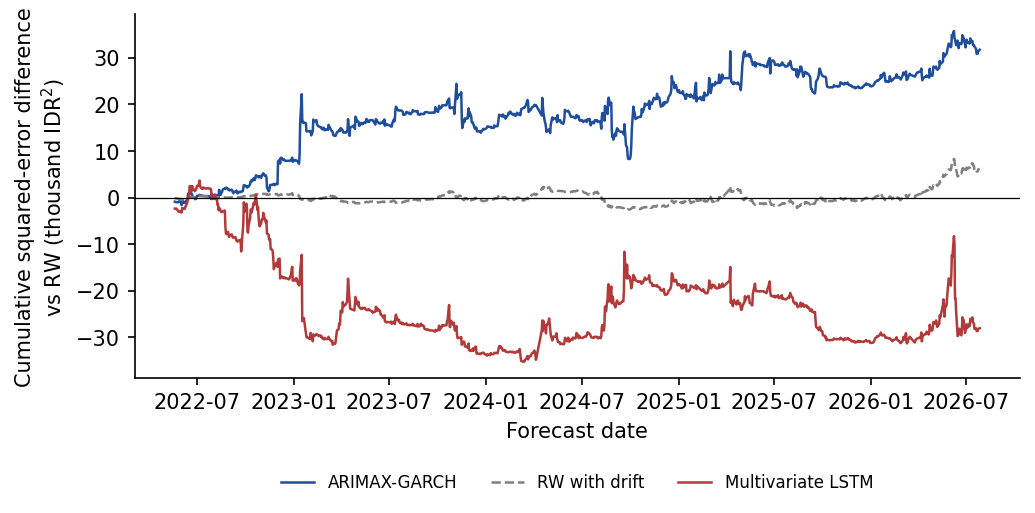

In [ ]:
y = fc["actual"].to_numpy()
dates = pd.to_datetime(fc["date"])
e_rw = (y - fc["rw"]) ** 2
fig, ax = plt.subplots(figsize=(7, 3.6), dpi=150)
for col, label, color, style in [("arimax", "ARIMAX-GARCH", "#1f4e9c", "-"),
                                 ("rw_drift", "RW with drift", "grey", "--"),
                                 ("lstm",
                                  "Multivariate LSTM", "#b23a3a", "-")]:
    gain = np.cumsum(e_rw - (y - fc[col]) ** 2) / 1000
    ax.plot(dates, gain, lw=1.2, color=color, ls=style, label=label)
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("Forecast date")
ax.set_ylabel("Cumulative squared-error difference\nvs RW (thousand IDR$^2$)")
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper center",
          bbox_to_anchor=(0.5, -0.22))
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig("figure2_cumulative_sse.png", dpi=600, bbox_inches="tight")
plt.show()

## Step 15: Subperiods and the bias-variance view of the LSTM
The forecasts of Step 10 are split into the monetary tightening phase (May 2022 to
June 2024) and the following phase (July 2024 to July 2026). The LSTM level errors
are then decomposed into squared bias and the rest, and the dispersion, correlation
and directional accuracy of the log-return forecasts are compared.

In [ ]:
d = pd.to_datetime(fc["date"])
y = fc["actual"].to_numpy()

# 1. Subperiods
rows = []
for name, mask in [("Tightening, May 2022 to Jun 2024", d < "2024-07-01"),
                   ("Post-tightening, Jul 2024 to Jul 2026", d >= "2024-07-01")]:
    sub = fc[mask.to_numpy()].reset_index(drop=True)
    acc = accuracy_table(sub).set_index("model")
    e1 = (sub["actual"] - sub["arimax"]).to_numpy()
    e2 = (sub["actual"] - sub["lstm"]).to_numpy()
    rows.append({"period": name, "n": len(sub),
                 "RMSE ARIMAX-GARCH": acc.loc["ARIMAX-GARCH", "RMSE"],
                 "RMSE LSTM": acc.loc["Multivariate LSTM", "RMSE"],
                 "HLN p (e^2)": hln_test(e1, e2, "squared")[1]})
display(pd.DataFrame(rows).round(4))

# 2. Bias-variance view of the LSTM level errors
e_lstm = y - fc["lstm"].to_numpy()
print("Mean LSTM level error (IDR):", round(e_lstm.mean(), 2))
print("Squared bias as % of MSE:", round(100 * e_lstm.mean() ** 2 / np.mean(e_lstm ** 2), 4))

# 3. Forecast dispersion, correlation with realized returns, direction
ra = fc["r_actual"].to_numpy()
for col, name in [("r_arimax", "ARIMAX-GARCH"), ("r_lstm", "Multivariate LSTM")]:
    f = fc[col].to_numpy()
    print(f"{name}: sd of forecasts = {f.std():.4f}%, corr with actual = {np.corrcoef(f, ra)[0, 1]:.3f}, "
          f"direction hit rate = {100 * np.mean(np.sign(f) == np.sign(ra)):.1f}%")
print("Share of |LSTM forecast| < 0.05%:", round(100 * np.mean(np.abs(fc["r_lstm"]) < 0.05), 1), "%")
print("Mean training epochs:", round(fc["epochs"].mean(), 1),
      "| windows reaching 100 epochs:", int((fc["epochs"] >= MAX_EPOCHS).sum()))

,period,n,RMSE ARIMAX-GARCH,RMSE LSTM,HLN p (e^2)
0,"Tightening, May 2022 to Jun 2024",507,54.5194,55.3545,0.0570
1,"Post-tightening, Jul 2024 to Jul 2026",496,56.8691,57.1029,0.5735


Mean LSTM level error (IDR): 0.27
Squared bias as % of MSE: 0.0023
ARIMAX-GARCH: sd of forecasts = 0.0440%, corr with actual = 0.093, direction hit rate = 51.6%
Multivariate LSTM: sd of forecasts = 0.0545%, corr with actual = 0.037, direction hit rate = 52.3%
Share of |LSTM forecast| < 0.05%: 75.8 %
Mean training epochs: 22.7 | windows reaching 100 epochs: 2


## Step 16: Sensitivity of the ARIMAX-GARCH
The main specification remains AR(1) with the CPI placed by its BPS release date.
This step changes one choice at a time to check whether the conclusions depend on
it. The first variant uses the AR(2) order of the earlier study, which was chosen
with information from the evaluation period and is therefore an upper bound. The
second variant places the CPI by its reference month, which is not available in
real time, to show that the release-date placement does not drive the results.
Each variant is compared with both random walks (Clark-West) and with the LSTM
forecasts of Step 10 (HLN). No LSTM is retrained in this step.

In [ ]:
def arimax_rolling(dW_used, ar_order, targets, k=K):
    """Rolling one-step ARIMAX-GARCH forecasts only (no LSTM), returned as levels and returns."""
    r_hat = []
    for target in targets:
        start = target - k
        res = arch_model(r[start:target], x=dW_used[start:target], mean="ARX", lags=ar_order,
                         vol="GARCH", p=1, q=1, dist="normal", rescale=False).fit(disp="off")
        r_hat.append(float(res.forecast(horizon=1, x=np.zeros((3, 1, 1)), reindex=False).mean.values[-1, 0]))
    r_hat = np.array(r_hat)
    return level[np.array(targets)] * np.exp(r_hat / 100), r_hat


def compare_variant(x_hat, r_hat, label):
    e_var = y - x_hat
    e_lstm = y - fc["lstm"].to_numpy()
    cw_rw = clark_west(ra, np.zeros(len(ra)), r_hat)[1]
    cw_rwd = clark_west(ra, fc["r_drift"].to_numpy(), r_hat)[1]
    return {"variant": label, "MAE": np.mean(np.abs(e_var)), "RMSE": np.sqrt(np.mean(e_var ** 2)),
            "MAPE (%)": 100 * np.mean(np.abs(e_var / y)),
            "CW p vs RW": cw_rw, "CW p vs RW-drift": cw_rwd,
            "HLN p vs LSTM (e^2)": hln_test(e_var, e_lstm, "squared")[1],
            "HLN p vs LSTM (|e|)": hln_test(e_var, e_lstm, "absolute")[1]}


targets_main = fc["target"].tolist()

# AR(2) order of the earlier study
x_ar2, r_ar2 = arimax_rolling(dW, 2, targets_main)

# CPI placed by its reference month (original file, without the release-month shift)
raw = pd.read_csv(DATA_PATH, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
dW_ref = np.column_stack([np.diff(raw[c].to_numpy(float)) for c in ["ffr", "bi", "cpi"]])
x_ref, r_ref = arimax_rolling(dW_ref, AR_ORDER, targets_main)

variants = pd.DataFrame([
    compare_variant(fc["arimax"].to_numpy(), fc["r_arimax"].to_numpy(), "AR(1), main"),
    compare_variant(x_ar2, r_ar2, "AR(2)"),
    compare_variant(x_ref, r_ref, "AR(1), CPI by reference month"),
])
variants.round(4)

,variant,MAE,RMSE,MAPE (%),CW p vs RW,CW p vs RW-drift,HLN p vs LSTM (e^2),HLN p vs LSTM (|e|)
0,"AR(1), main",41.1936,55.6937,0.2589,0.0023,0.0063,0.0779,0.2786
1,AR(2),40.9091,55.4358,0.2572,0.0000,0.0001,0.0365,0.0707
2,"AR(1), CPI by reference month",41.1778,55.6873,0.2589,0.0022,0.0062,0.0716,0.2492


## Step 17: Sensitivity of the LSTM
The LSTM is retrained with 64 units on all 1,003 origins, and with a second seed (7)
on 201 origins taken every fifth trading day.

In [ ]:
# 1. LSTM with 64 units on all origins (about 3 to 4 hours)
UNITS_MAIN = UNITS
UNITS = 64
fc64 = rolling_forecasts(K, targets_main, "forecasts_k1000_u64.csv")
UNITS = UNITS_MAIN
e_arimax = (fc["actual"] - fc["arimax"]).to_numpy()
e_64 = (fc64["actual"] - fc64["lstm"]).to_numpy()
display(accuracy_table(fc64).round(4))
print("HLN ARIMAX-GARCH vs LSTM u=64 (e^2):", hln_test(e_arimax, e_64, "squared"))
print("HLN ARIMAX-GARCH vs LSTM u=64 (|e|):", hln_test(e_arimax, e_64, "absolute"))
print("HLN RW vs LSTM u=64 (e^2):", hln_test((fc["actual"] - fc["rw"]).to_numpy(), e_64, "squared"))

# 2. Second seed on every fifth origin (about 35 minutes)
targets_seed = targets_main[::5]
fc_s7 = rolling_forecasts(K, targets_seed, "forecasts_k1000_seed7.csv", seed=7)
sub = fc[fc["target"].isin(targets_seed)].reset_index(drop=True)
rmse = lambda x: np.sqrt(np.mean((sub["actual"].to_numpy() - np.asarray(x)) ** 2))
print("Origins:", len(sub))
print("Correlation of LSTM forecasts, seed 42 vs 7:", round(np.corrcoef(sub["r_lstm"], fc_s7["r_lstm"])[0, 1], 3))
print("RMSE LSTM seed 42:", round(rmse(sub["lstm"]), 2), "| seed 7:", round(rmse(fc_s7["lstm"]), 2),
      "| average:", round(rmse((sub["lstm"] + fc_s7["lstm"]) / 2), 2))
print("RMSE ARIMAX-GARCH:", round(rmse(sub["arimax"]), 2), "| RW:", round(rmse(sub["rw"]), 2),
      "| RW-drift:", round(rmse(sub["rw_drift"]), 2))

saved up to 2022-06-06
saved up to 2022-06-20
saved up to 2026-01-15
saved up to 2026-01-30
saved up to 2026-02-13
saved up to 2026-03-03
saved up to 2026-03-17
saved up to 2026-04-08
saved up to 2026-04-22
saved up to 2026-05-07
saved up to 2026-05-25
saved up to 2026-06-11
saved up to 2026-06-26
saved up to 2026-07-10
saved up to 2026-07-24


,model,MAE,RMSE,MAPE (%),RMSE vs RW (%)
0,RW without drift,41.1386,55.9770,0.2586,0.0000
1,RW with drift,40.9835,55.9220,0.2577,-0.0983
2,ARIMAX-GARCH,41.1936,55.6937,0.2589,-0.5061
3,Multivariate LSTM,41.5769,56.3311,0.2615,0.6325


HLN ARIMAX-GARCH vs LSTM u=64 (e^2): (np.float64(-2.312846679055247), np.float64(0.02093288599755913))
HLN ARIMAX-GARCH vs LSTM u=64 (|e|): (np.float64(-1.5647069019950057), np.float64(0.11796739621464346))
HLN RW vs LSTM u=64 (e^2): (np.float64(-1.1392349156852006), np.float64(0.2548774606166717))
saved up to 2026-02-05
saved up to 2026-04-28
saved up to 2026-07-16
Origins: 201
Correlation of LSTM forecasts, seed 42 vs 7: 0.822
RMSE LSTM seed 42: 57.03 | seed 7: 56.87 | average: 56.9
RMSE ARIMAX-GARCH: 56.1 | RW: 56.05 | RW-drift: 55.99


## Step 18: Cross-window distribution of the ARIMAX-GARCH estimates
The estimates in Step 7 come from the first window only. This step re-estimates
the ARIMAX(1)-GARCH(1,1) on all 1,004 rolling windows of 1,000 days with robust
standard errors and summarizes each coefficient by its mean, its standard
deviation, the share of windows with a positive estimate, and the share of
windows in which it is significant at the 5% level. A coefficient that keeps its
sign and significance across windows is stable, while one that changes sign or is
rarely significant contributes little to the forecasts. The results fill the last
column of Table I.

In [ ]:
# Cross-window distribution of the ARIMAX-GARCH estimates (Table I, last column)
rows = []
for start in range(0, n_ret - K + 1):
    res = arch_model(r[start:start + K], x=dW[start:start + K], mean="ARX", lags=AR_ORDER, vol="GARCH",
                     p=1, q=1, dist="normal", rescale=False).fit(disp="off", cov_type="robust")
    rows.append(pd.concat([res.params.add_prefix("coef_"), res.pvalues.add_prefix("p_")]))
cross = pd.DataFrame(rows)
names = ["Const", "y[1]", "x0", "x1", "x2", "omega", "alpha[1]", "beta[1]"]
labels = ["c", "phi1", "xi1 (dFFR)", "xi2 (dBI)", "xi3 (dCPI)", "omega", "alpha1", "beta1"]
cross_table = pd.DataFrame({
    "mean": [cross[f"coef_{n}"].mean() for n in names],
    "sd": [cross[f"coef_{n}"].std() for n in names],
    "% coef > 0": [100 * (cross[f"coef_{n}"] > 0).mean() for n in names],
    "% p < 0.05": [100 * (cross[f"p_{n}"] < 0.05).mean() for n in names],
}, index=labels)
persist = cross["coef_alpha[1]"] + cross["coef_beta[1]"]
print("Windows:", len(cross))
print("alpha1 + beta1 across windows: min", round(persist.min(), 4), "| max", round(persist.max(), 4))
cross_table.round(4)

Windows: 1004
alpha1 + beta1 across windows: min 0.9171 | max 0.9855


,mean,sd,% coef > 0,% p < 0.05
c,0.0087,0.0078,79.8805,8.8645
phi1,0.1199,0.0119,100.0000,100.0000
xi1 (dFFR),-0.2856,0.1707,4.7809,0.0000
xi2 (dBI),0.5325,0.2000,96.3147,52.8884
xi3 (dCPI),0.0933,0.0894,90.6375,0.0000
omega,0.0043,0.0013,100.0000,0.7968
alpha1,0.1049,0.0205,100.0000,57.6693
beta1,0.8647,0.0235,100.0000,100.0000


## Step 19: Descriptive figures
This step draws three figures for the thesis. The first shows the JISDOR IDR/USD
rate over the full sample. The second shows the daily log returns in panel (a)
and their distribution against a fitted normal density in panel (b), which
illustrates volatility clustering and heavy tails. The third compares the actual
rate with the one-day-ahead forecasts of the ARIMAX-GARCH, the LSTM, and the
random walk over the last 120 origins. Each figure is saved at 600 dpi in the
working folder.

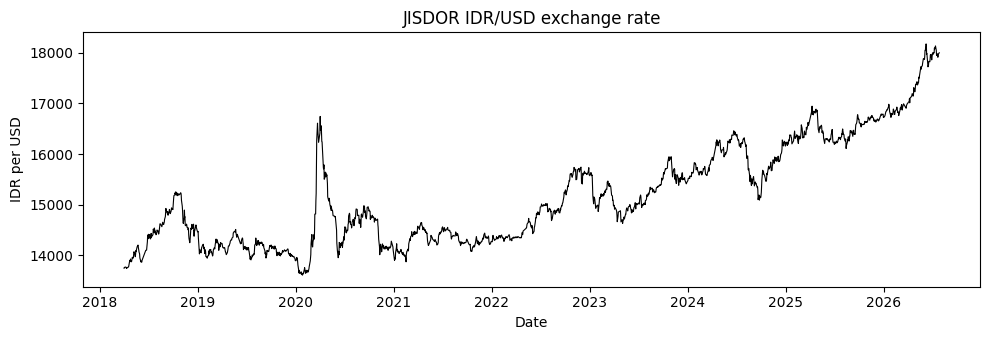

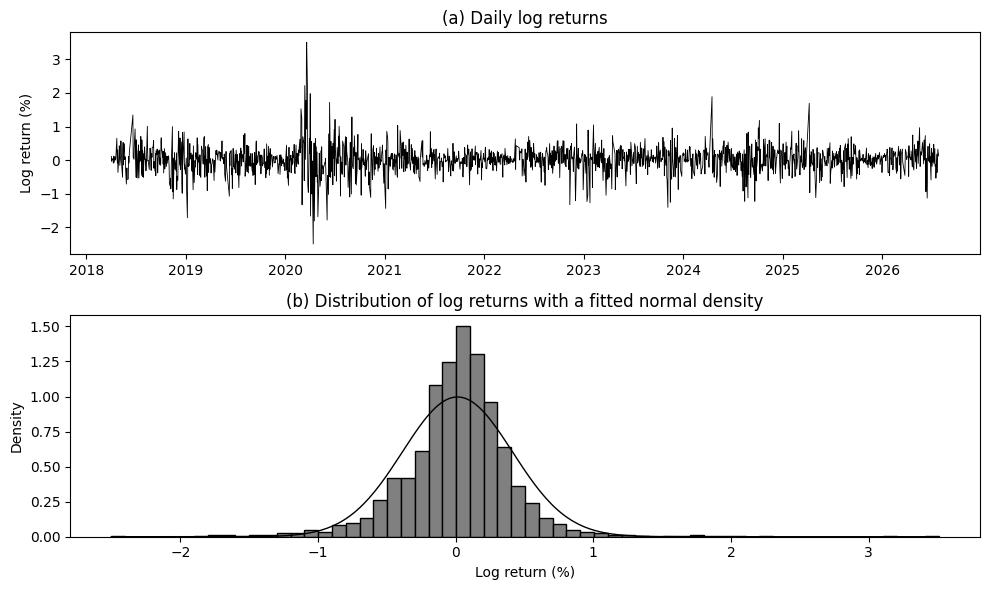

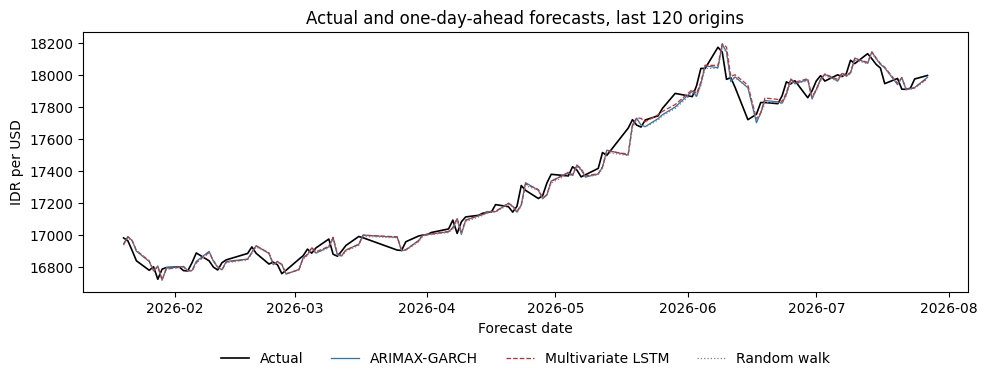

In [ ]:
# Figures: exchange rate, log returns, and actual versus forecast over the last 120 days
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(df["date"], df["fx"], color="black", lw=0.8)
ax.set_xlabel("Date")
ax.set_ylabel("IDR per USD")
ax.set_title("JISDOR IDR/USD exchange rate")
fig.tight_layout()
fig.savefig("figure_exchange_rate.png", dpi=600)
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
axes[0].plot(ret_dates, r, color="black", lw=0.6)
axes[0].set_ylabel("Log return (%)")
axes[0].set_title("(a) Daily log returns")
axes[1].hist(r, bins=60, color="grey", edgecolor="black", density=True)
grid = np.linspace(r.min(), r.max(), 300)
axes[1].plot(grid, stats.norm.pdf(grid, r.mean(), r.std()), color="black", lw=1)
axes[1].set_xlabel("Log return (%)")
axes[1].set_ylabel("Density")
axes[1].set_title("(b) Distribution of log returns with a fitted normal density")
fig.tight_layout()
fig.savefig("figure_log_returns.png", dpi=600)
plt.show()

last = fc.tail(120)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pd.to_datetime(last["date"]), last["actual"], color="black", lw=1.2, label="Actual")
ax.plot(pd.to_datetime(last["date"]), last["arimax"], color="tab:blue", lw=0.9, label="ARIMAX-GARCH")
ax.plot(pd.to_datetime(last["date"]), last["lstm"], color="tab:red", lw=0.9, ls="--", label="Multivariate LSTM")
ax.plot(pd.to_datetime(last["date"]), last["rw"], color="grey", lw=0.9, ls=":", label="Random walk")
ax.set_xlabel("Forecast date")
ax.set_ylabel("IDR per USD")
ax.set_title("Actual and one-day-ahead forecasts, last 120 origins")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, frameon=False)
fig.tight_layout()
fig.savefig("figure_actual_vs_forecast.png", dpi=600, bbox_inches="tight")
plt.show()

## Step 20: Supporting statistics
This step computes three quantities quoted in the text. The first is the mean
absolute percentage change of the rate in each year, which equals the MAPE of the
random walk and shows how calm or turbulent each year was. The second is the
number of days in each window on which the policy rates and the CPI actually
change, since the regressors enter as first differences and are zero on most
days. The third is an approximate standard error of each regressor coefficient in
the first window, which shows how little information these sparse differences
carry.

In [ ]:
# 1. Mean absolute percentage change of the rate per year (MAPE of the random walk)
rw_ape = 100 * np.abs(np.diff(level)) / level[1:]
yearly = pd.Series(rw_ape, index=ret_dates.dt.year.values).groupby(level=0).mean()
print("Random-walk MAPE (%) by year:\n", yearly.round(3))

# 2. Number of days with a nonzero regressor difference per window
nonzero = np.array([[np.count_nonzero(dW[s:s + K, j]) for j in range(3)] for s in range(n_ret - K + 1)])
print("\nMean nonzero days per window (dFFR, dBI, dCPI):", nonzero.mean(axis=0).round(1))
print("Share of zero days over the full sample (%):", (100 * (dW == 0).mean(axis=0)).round(1))

# 3. Approximate standard error of each regressor coefficient in the first window
approx_se = np.std(r[:K], ddof=1) / np.sqrt((dW[:K] ** 2).sum(axis=0))
print("Approximate SE (dFFR, dBI, dCPI):", approx_se.round(3))

Random-walk MAPE (%) by year:
 2018    0.311
2019    0.244
2020    0.472
2021    0.211
2022    0.206
2023    0.274
2024    0.288
2025    0.237
2026    0.239
dtype: float64

Mean nonzero days per window (dFFR, dBI, dCPI): [13.7 13.5 49.5]
Share of zero days over the full sample (%): [98.8 98.4 95.1]
Approximate SE (dFFR, dBI, dCPI): [0.319 0.407 0.179]


## Step 21: Article figures in high resolution
This step redraws Figures 1 and 2 at their printed width of 8 cm, so the font sizes in the code are
the printed sizes. Each figure is saved as a 600 dpi PNG, a 600 dpi TIFF, and a vector PDF in the
folder article_figures_hd, and the folder is downloaded as a zip file.

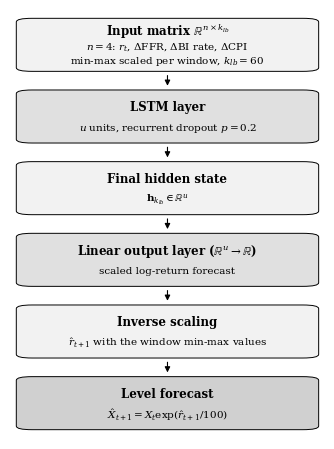

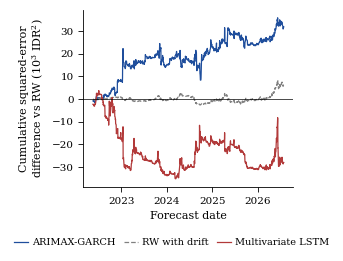

Files: ['figure1_lstm_architecture.pdf', 'figure1_lstm_architecture.png', 'figure1_lstm_architecture.tiff', 'figure2_cumulative_sse.pdf', 'figure2_cumulative_sse.png', 'figure2_cumulative_sse.tiff']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# Article figures in high resolution (600 dpi PNG and TIFF, plus vector PDF)
# Each figure is drawn at its printed width (8 cm column), so the font sizes below are the printed sizes.
import os, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

plt.rcParams.update({
    "font.family": "DejaVu Serif", "mathtext.fontset": "dejavuserif",
    "font.size": 8, "axes.labelsize": 8, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5, "axes.linewidth": 0.6,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "pdf.fonttype": 42,
})
WIDTH_IN = 8.0 / 2.54          # printed width in the article (8 cm)
OUT_DIR = "article_figures_hd"
os.makedirs(OUT_DIR, exist_ok=True)


def save_all(fig, name):
    """Save one figure as 600 dpi PNG, 600 dpi TIFF, and vector PDF."""
    for ext in ["png", "tiff", "pdf"]:
        kwargs = {"pil_kwargs": {"compression": "tiff_lzw"}} if ext == "tiff" else {}
        fig.savefig(os.path.join(OUT_DIR, f"{name}.{ext}"), dpi=600,
                    bbox_inches="tight", pad_inches=0.03, **kwargs)


# Figure 1: architecture of the multivariate LSTM
boxes = [
    ("Input matrix $\\mathbb{R}^{n \\times k_{lb}}$",
     "$n=4$: $r_t$, $\\Delta$FFR, $\\Delta$BI rate, $\\Delta$CPI\nmin-max scaled per window, $k_{lb}=60$", "#f2f2f2"),
    ("LSTM layer", "$u$ units, recurrent dropout $p=0.2$", "#e0e0e0"),
    ("Final hidden state", "$\\mathbf{h}_{k_{lb}} \\in \\mathbb{R}^{u}$", "#f2f2f2"),
    ("Linear output layer ($\\mathbb{R}^{u} \\rightarrow \\mathbb{R}$)", "scaled log-return forecast", "#e0e0e0"),
    ("Inverse scaling", "$\\hat{r}_{t+1}$ with the window min-max values", "#f2f2f2"),
    ("Level forecast", "$\\hat{X}_{t+1} = X_t \\exp(\\hat{r}_{t+1}/100)$", "#d0d0d0"),
]
fig, ax = plt.subplots(figsize=(WIDTH_IN, 4.3))
fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
ax.set_xlim(0, 1)
ax.set_ylim(0, len(boxes))
ax.axis("off")
h = 0.74
for i, (title, body, color) in enumerate(boxes):
    y = len(boxes) - i - 1 + (1 - h) / 2
    ax.add_patch(FancyBboxPatch((0.02, y), 0.96, h, boxstyle="round,pad=0.0,rounding_size=0.05",
                                fc=color, ec="black", lw=0.7))
    two_lines = "\n" in body
    ax.text(0.5, y + h * (0.76 if two_lines else 0.68), title, ha="center", va="center",
            fontsize=8.5, weight="bold")
    ax.text(0.5, y + h * (0.33 if two_lines else 0.30), body, ha="center", va="center",
            fontsize=7.5, linespacing=1.25)
    if i < len(boxes) - 1:
        ax.annotate("", xy=(0.5, y - (1 - h) + 0.02), xytext=(0.5, y - 0.02),
                    arrowprops=dict(arrowstyle="-|>", lw=0.8, color="black"))
save_all(fig, "figure1_lstm_architecture")
plt.show()

# Figure 2: cumulative squared-error difference relative to the random walk
fc_fig = pd.read_csv("forecasts_k1000.csv").sort_values("target").reset_index(drop=True)
y_fig = fc_fig["actual"].to_numpy()
dates_fig = pd.to_datetime(fc_fig["date"])
e_rw = (y_fig - fc_fig["rw"].to_numpy()) ** 2
fig, ax = plt.subplots(figsize=(WIDTH_IN * 0.86, 2.3))   # the y label adds the remaining width
for col, label, color, style in [("arimax", "ARIMAX-GARCH", "#1f4e9c", "-"),
                                 ("rw_drift", "RW with drift", "grey", "--"),
                                 ("lstm", "Multivariate LSTM", "#b23a3a", "-")]:
    gain = np.cumsum(e_rw - (y_fig - fc_fig[col].to_numpy()) ** 2) / 1000
    ax.plot(dates_fig, gain, lw=0.9, color=color, ls=style, label=label)
ax.axhline(0, color="black", lw=0.5)
ax.set_xlabel("Forecast date")
ax.set_ylabel("Cumulative squared-error\ndifference vs RW (10$^3$ IDR$^2$)")
ax.xaxis.set_major_locator(plt.matplotlib.dates.YearLocator())
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%Y"))
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.42, -0.24),
          fontsize=7, handlelength=1.5, handletextpad=0.4, columnspacing=0.8)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
save_all(fig, "figure2_cumulative_sse")
plt.show()

# Zip and download
zip_name = "article_figures_hd.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(os.listdir(OUT_DIR)):
        z.write(os.path.join(OUT_DIR, f), arcname=f)
print("Files:", sorted(os.listdir(OUT_DIR)))
try:
    from google.colab import files
    files.download(zip_name)
except ImportError:
    print("Saved", zip_name)


## Step 22: Package versions
This step records the Python version and the versions of the main packages, and writes them to
requirements.txt so the environment of the article can be rebuilt.

In [4]:
import sys, importlib.metadata as md
packages = ["numpy", "pandas", "scipy", "matplotlib", "arch", "statsmodels", "keras", "jax", "jaxlib"]
print("Python", sys.version.split()[0])
lines = [f"{p}=={md.version(p)}" for p in packages]
print("\n".join(lines))
with open("requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")
try:
    from google.colab import files
    files.download("requirements.txt")
except ImportError:
    pass

Python 3.13.18
numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
matplotlib==3.10.0
arch==8.0.0
statsmodels==0.15.0
keras==3.13.2
jax==0.11.1
jaxlib==0.11.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>